In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split, GridSearchCV,StratifiedKFold
from sklearn.preprocessing import StandardScaler, PowerTransformer,MinMaxScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay
)


In [ ]:
df = pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# EDA

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


**Finidngs**
- This dataset focuses on adults from 21 to 81.
- All Data types are appropriate.
- Features have different scales.

## Missing Values & Duplicates

In [ ]:
df.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
df.duplicated().sum()

np.int64(0)

Great! No missing or duplicated values.

## Relations Analysis

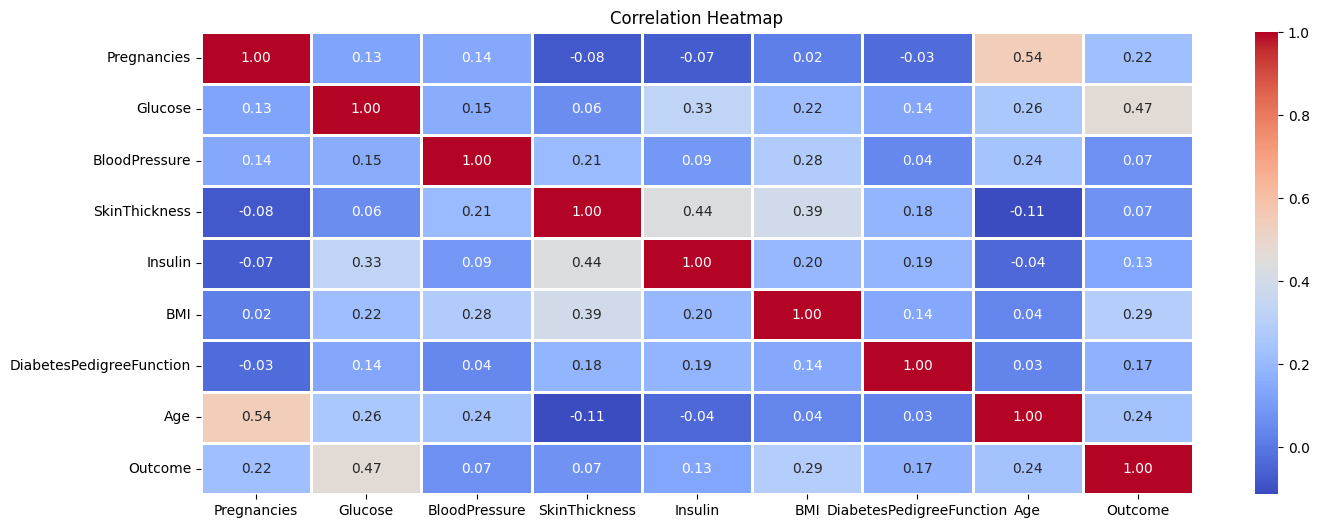

In [ ]:
# correlation heat map
plt.figure(figsize=(16,6))
sns.heatmap(df.corr(),annot=True,fmt='.2f',cmap='coolwarm',linewidths=2)
plt.title('Correlation Heatmap')
plt.show()


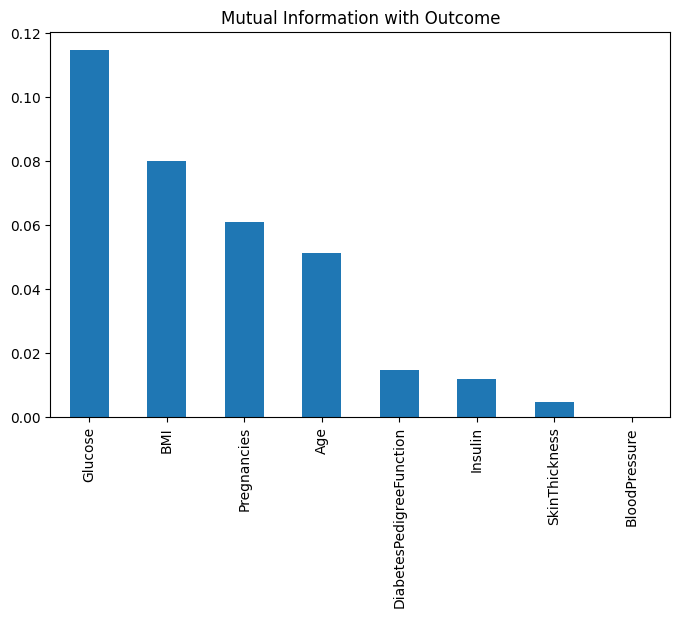

In [ ]:
train = df.drop('Outcome', axis=1)
target = df['Outcome']
mi = mutual_info_classif(train, target, random_state=42)
mi_series = pd.Series(mi, index=train.columns).sort_values(ascending=False)
mi_series.plot(kind="bar", figsize=(8,5), title="Mutual Information with Outcome")
plt.show()

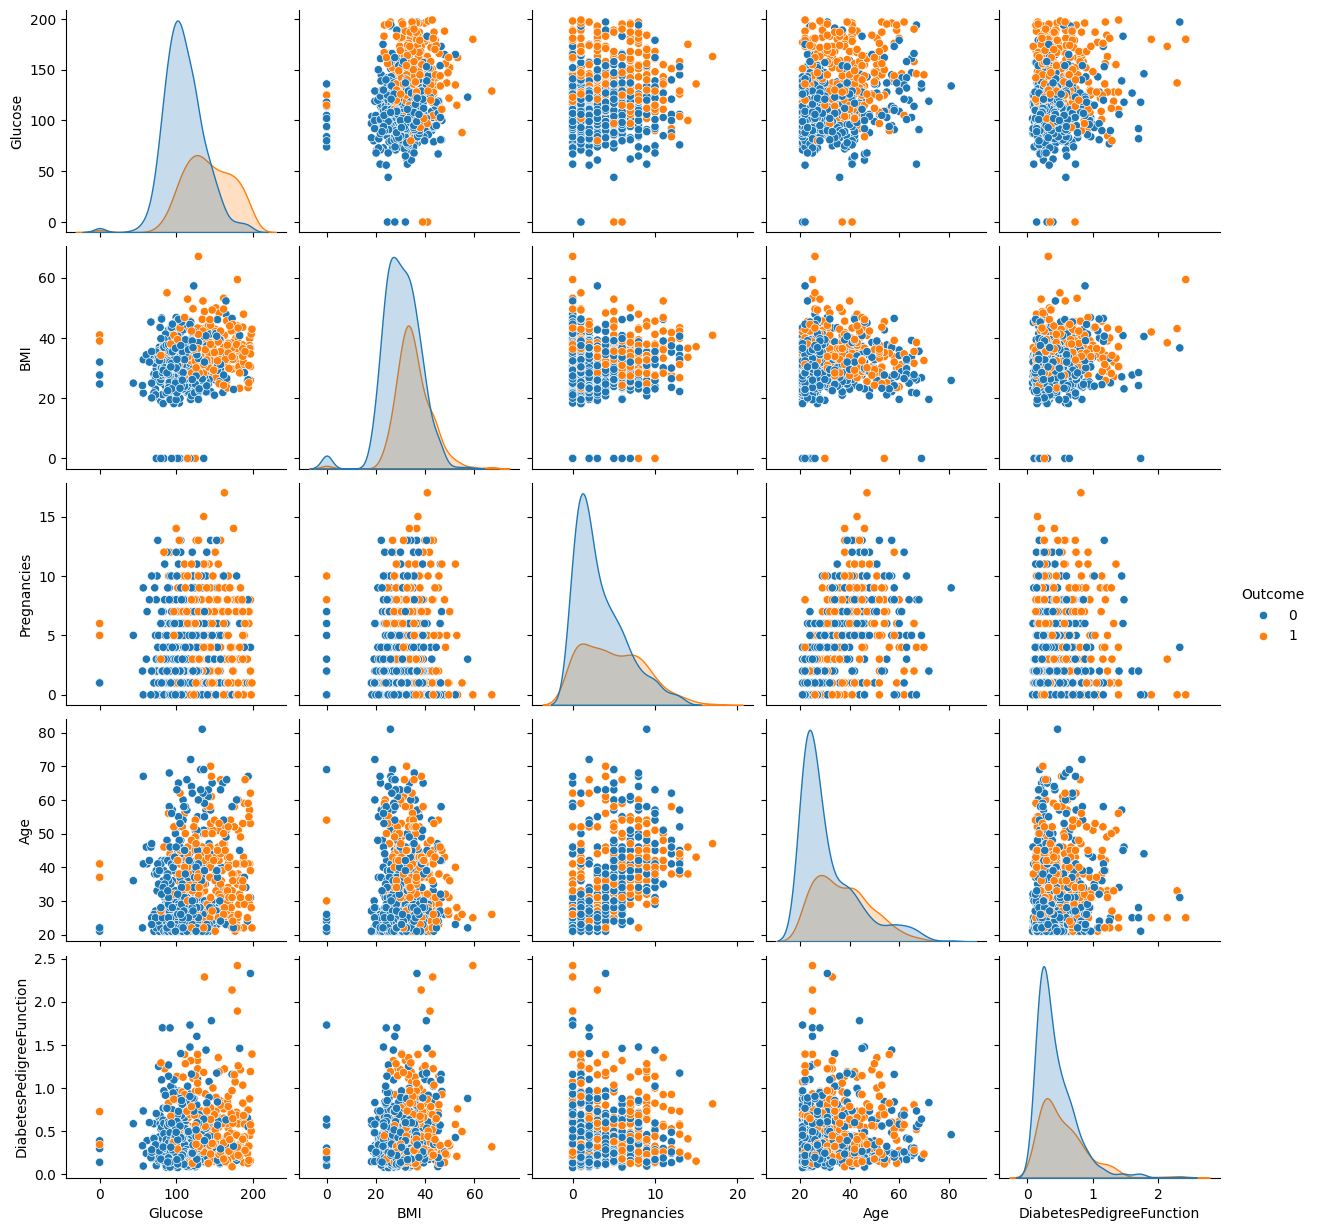

In [ ]:
# Pair plot of top correlated features
top_features = mi_series.head(5).index  # pick top 3 by MI
sns.pairplot(df[top_features.tolist() + ["Outcome"]], hue="Outcome", diag_kind="kde")
plt.show()


**Relations Analysis Findings**

**Linear correlations (Pearson)**

Glucose (r ≈ 0.47) shows the strongest linear relationship with diabetes outcome.

BMI (r ≈ 0.29), Age (r ≈ 0.24), and Pregnancies (r ≈ 0.22) have moderate positive correlations.

Other features (Insulin, SkinThickness, BloodPressure, DiabetesPedigreeFunction) exhibit weak linear correlations (< 0.20).

**Non-linear dependencies (Mutual Information)**

Glucose contributes the most predictive power (~0.11).

BMI, Pregnancies, and Age follow, confirming their relevance beyond linear effects.

Insulin and SkinThickness rank low in MI, suggesting limited direct predictive contribution.

**Multicollinearity checks**

Correlation heatmap shows Insulin and SkinThickness (r ≈ 0.44) are moderately correlated.

Pregnancies and Age (r ≈ 0.54) are strongly correlated.

This means multicollinearity may exist, so regularization (L1/L2) or feature selection should be considered.

# Feature Engineering

In [ ]:
df["Glucose_BMI"] = df["Glucose"] * df["BMI"]
df["Age_BMI"] = df["Age"] * df["BMI"]

df["Insulin_Glucose_Ratio"] = df["Insulin"] / (df["Glucose"] + 1e-5)
df["SkinThickness_BMI_Ratio"] = df["SkinThickness"] / (df["BMI"] + 1e-5)

df["Age_Pregnancies"] = df["Age"] * df["Pregnancies"]


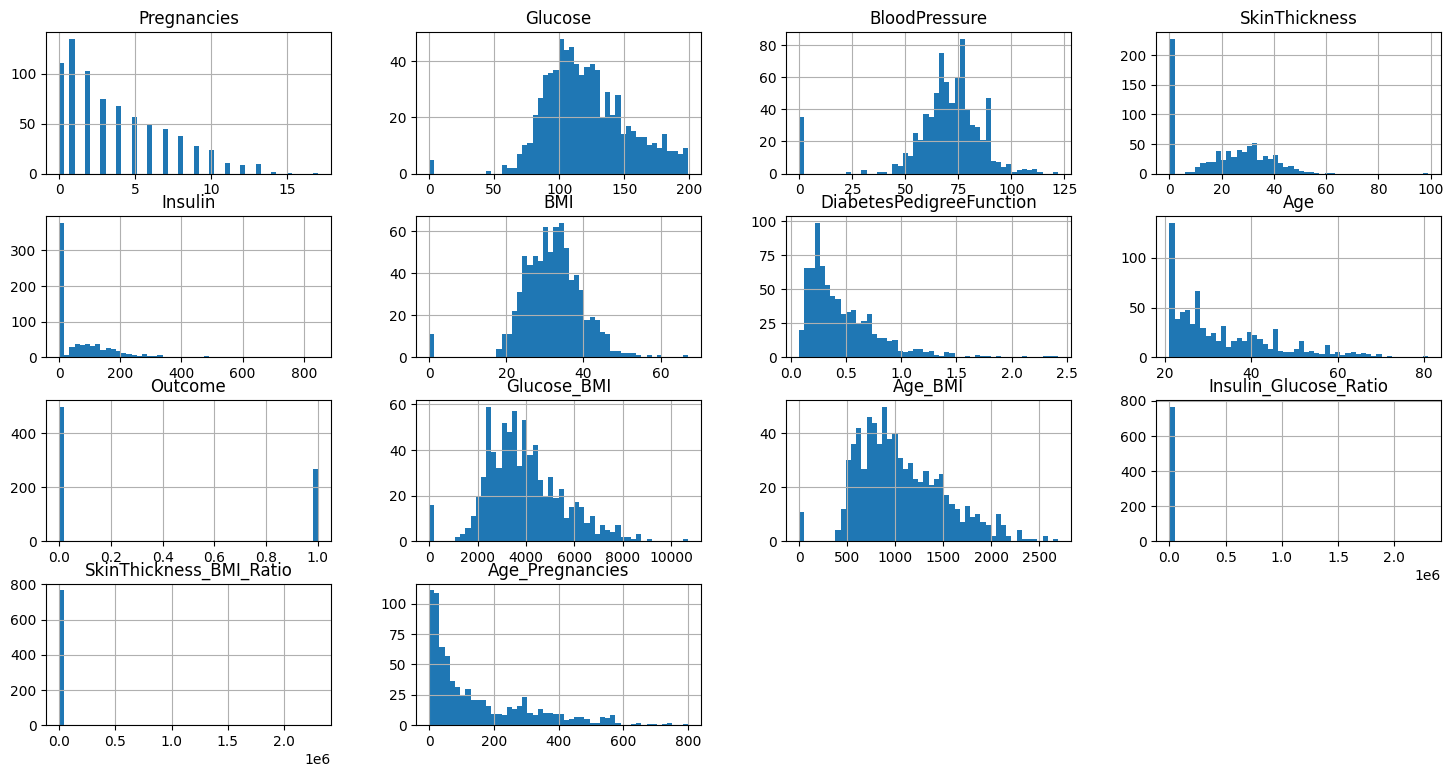

In [ ]:
df.hist(figsize=(18,9),bins=50)
plt.show()

In [ ]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

In [ ]:
y.value_counts()

,count
Outcome,
0,500
1,268


classes are not balanced

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Model Selection


Model: Logistic Regression
Confusion Matrix:
 [[75 25]
 [16 38]]
Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154

Model: SVM (RBF Kernel)
Confusion Matrix:
 [[73 27]
 [13 41]]
Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.73      0.78       100
           1       0.60      0.76      0.67        54

    accuracy                           0.74       154
   macro avg       0.73      0.74      0.73       154
weighted avg       0.76      0.74      0.75       154

Model: Random Forest
Confusion Matrix:
 [[77 23]
 [20 34]]
Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.77

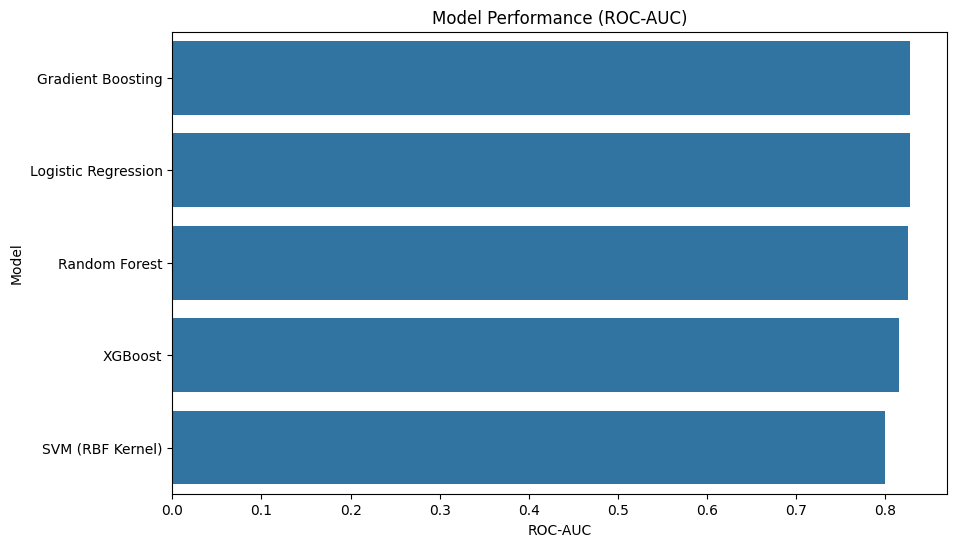

In [ ]:


models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM (RBF Kernel)": SVC(kernel="rbf", probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric="logloss", random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train_res, y_train_res)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_prob)

    results.append([name, acc, prec, rec, f1, roc])

    print("="*50)
    print(f"Model: {name}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))


results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"])
print("\n📊 Model Comparison:\n")
print(results_df.sort_values(by="ROC-AUC", ascending=False))

# Plot comparison
plt.figure(figsize=(10,6))
sns.barplot(x="ROC-AUC", y="Model", data=results_df.sort_values("ROC-AUC", ascending=False))
plt.title("Model Performance (ROC-AUC)")
plt.show()

# Hyperparameter Tuning

In [ ]:
'''
svm_param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto', 0.01, 0.001],
    'kernel': ['rbf', 'poly', 'sigmoid']
}

# Stratified K-Fold
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# GridSearchCV
svm_grid = GridSearchCV(
    SVC(probability=True, random_state=42),
    svm_param_grid,
    scoring='f1',
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

# Fit on training set
svm_grid.fit(X_train, y_train)

# Best model
best_svm = svm_grid.best_estimator_

# Test evaluation
y_pred_svm = best_svm.predict(X_test)
y_prob_svm = best_svm.predict_proba(X_test)[:, 1]

print("🔹 Best SVM Parameters:", svm_grid.best_params_)
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_svm))'''


'\nsvm_param_grid = {\n    \'C\': [0.1, 1, 10],\n    \'gamma\': [\'scale\', \'auto\', 0.01, 0.001],\n    \'kernel\': [\'rbf\', \'poly\', \'sigmoid\']\n}\n\n# Stratified K-Fold\ncv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)\n\n# GridSearchCV\nsvm_grid = GridSearchCV(\n    SVC(probability=True, random_state=42),\n    svm_param_grid,\n    scoring=\'f1\',\n    cv=cv_strategy,\n    n_jobs=-1,\n    verbose=1\n)\n\n# Fit on training set\nsvm_grid.fit(X_train, y_train)\n\n# Best model\nbest_svm = svm_grid.best_estimator_\n\n# Test evaluation\ny_pred_svm = best_svm.predict(X_test)\ny_prob_svm = best_svm.predict_proba(X_test)[:, 1]\n\nprint("🔹 Best SVM Parameters:", svm_grid.best_params_)\nprint("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))\nprint("\nClassification Report:\n", classification_report(y_test, y_pred_svm))\nprint("ROC-AUC:", roc_auc_score(y_test, y_prob_svm))'

# Final Model

In [ ]:
final_model = SVC(probability=True, random_state=42, C=10, gamma=0.01, kernel='sigmoid')
final_model.fit(X_train, y_train)

SVC(C=10, gamma=0.01, kernel='sigmoid', probability=True, random_state=42)

In [ ]:
y_pred_svm = final_model.predict(X_test)
y_prob_svm = final_model.predict_proba(X_test)[:, 1]

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_svm))


Confusion Matrix:
 [[83 17]
 [26 28]]

Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.83      0.79       100
           1       0.62      0.52      0.57        54

    accuracy                           0.72       154
   macro avg       0.69      0.67      0.68       154
weighted avg       0.71      0.72      0.71       154

ROC-AUC: 0.8264814814814815
